In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

# load the dataset

In [12]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sherrytp/consumer-complaints")

print("Path to dataset files:", path)

100%|██████████| 501M/501M [00:08<00:00, 63.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sherrytp/consumer-complaints/versions/2


# load data into data frame

In [18]:
csv_file = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]

df = pd.read_csv(csv_file, low_memory=False)

# Display DataFrame
display(df.head())

print("Dataset Shape:", df.shape)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,2022-11-19,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,NaN,"EQUIFAX, INC.",TX,78541,Servicemember,NaN,Web,2022-11-19,In progress,Yes,NaN,6222374
1,2022-10-13,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Improper use of your report,Reporting company used your report improperly,In accordance with the fair credit reporting act XXXX account XXXX XXXX # XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX X...,Company has responded to the consumer and the CFPB and chooses not to provide a public response,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",GA,30043,NaN,Consent provided,Web,2022-10-13,Closed with explanation,Yes,NaN,6079679
2,2022-10-13,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Information belongs to someone else,This is not a duplicate nor is this complaint filed by a third party. I am filing this complaint myself. Please see this complaint is processed to...,Company has responded to the consumer and the CFPB and chooses not to provide a public response,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",CA,90660,NaN,Consent provided,Web,2022-10-13,Closed with non-monetary relief,Yes,NaN,6076990
3,2022-10-12,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Personal information incorrect,NaN,Company has responded to the consumer and the CFPB and chooses not to provide a public response,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",PA,19148,NaN,Consent not provided,Web,2022-10-12,Closed with non-monetary relief,Yes,NaN,6080312
4,2022-11-19,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,NaN,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",OH,44130,NaN,NaN,Web,2022-11-19,In progress,Yes,NaN,6222634


Dataset Shape: (3093136, 18)


In [19]:
df.head(3).T


,0,1,2
Date received,2022-11-19,2022-10-13,2022-10-13
Product,"Credit reporting, credit repair services, or other personal consumer reports","Credit reporting, credit repair services, or other personal consumer reports","Credit reporting, credit repair services, or other personal consumer reports"
Sub-product,Credit reporting,Credit reporting,Credit reporting
Issue,Improper use of your report,Improper use of your report,Incorrect information on your report
Sub-issue,Reporting company used your report improperly,Reporting company used your report improperly,Information belongs to someone else
Consumer complaint narrative,NaN,In accordance with the fair credit reporting act XXXX account XXXX XXXX # XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX X...,This is not a duplicate nor is this complaint filed by a third party. I am filing this complaint myself. Please see this complaint is processed to...
Company public response,NaN,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Company has responded to the consumer and the CFPB and chooses not to provide a public response
Company,"EQUIFAX, INC.","TRANSUNION INTERMEDIATE HOLDINGS, INC.","TRANSUNION INTERMEDIATE HOLDINGS, INC."
State,TX,GA,CA
ZIP code,78541,30043,90660


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3093136 entries, 0 to 3093135
Data columns (total 18 columns):
 #   Column                        Dtype 
---  ------                        ----- 
 0   Date received                 object
 1   Product                       object
 2   Sub-product                   object
 3   Issue                         object
 4   Sub-issue                     object
 5   Consumer complaint narrative  object
 6   Company public response       object
 7   Company                       object
 8   State                         object
 9   ZIP code                      object
 10  Tags                          object
 11  Consumer consent provided?    object
 12  Submitted via                 object
 13  Date sent to company          object
 14  Company response to consumer  object
 15  Timely response?              object
 16  Consumer disputed?            object
 17  Complaint ID                  int64 
dtypes: int64(1), object(17)
memory usage: 424.

# checking the null values

In [21]:
df.isnull().sum()

,0
Date received,0
Product,0
Sub-product,235294
Issue,0
Sub-issue,682938
Consumer complaint narrative,1981806
Company public response,1748880
Company,0
State,40001
ZIP code,40429


# there are  1981806 null vales are present in the Consumer complaint narrative

# checking the missing values percentage / Null values percentage

In [23]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing

,Missing Values,Missing Percentage
Tags,2742421,88.661507
Consumer disputed?,2324693,75.156508
Consumer complaint narrative,1981806,64.071092
Company public response,1748880,56.540676
Consumer consent provided?,819618,26.497962
Sub-issue,682938,22.079146
Sub-product,235294,7.606972
ZIP code,40429,1.307055
State,40001,1.293218
Company response to consumer,4,0.000129


# visualizaton of missing value / Null values

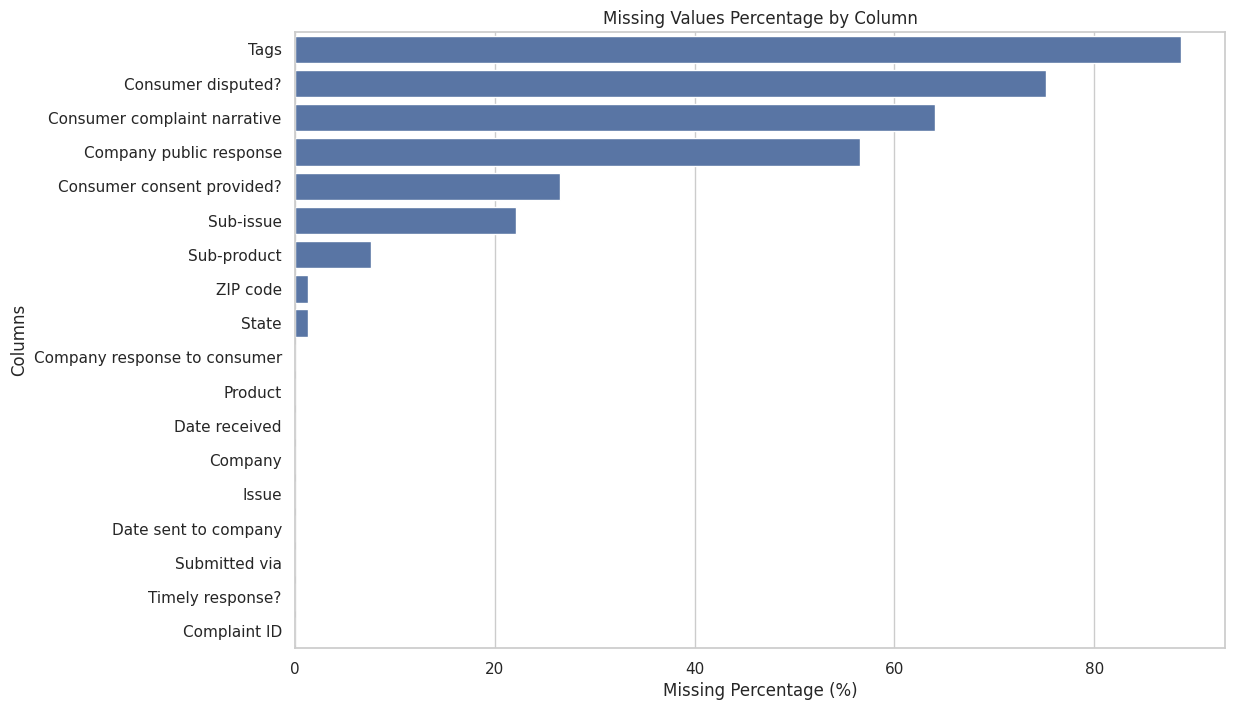

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    x=missing['Missing Percentage'],
    y=missing.index
)

plt.title('Missing Values Percentage by Column')
plt.xlabel('Missing Percentage (%)')
plt.ylabel('Columns')
plt.show()

In [25]:
print("Total records:", len(df))

print(
    "Available narratives:",
    df['Consumer complaint narrative'].notna().sum()
)

print(
    "Missing narratives:",
    df['Consumer complaint narrative'].isna().sum()
)

print(
    "Narrative availability:",
    df['Consumer complaint narrative'].notna().mean() * 100,
    "%"
)

Total records: 3093136
Available narratives: 1111330
Missing narratives: 1981806
Narrative availability: 35.92890839588043 %


In [27]:
nlp_df = df[
    [
        'Consumer complaint narrative',
        'Product'
    ]
].copy()

print("Before cleaning:", nlp_df.shape)

Before cleaning: (3093136, 2)


# before removing the null values from the dataset there are 3093136 rows are pressent

# Removing the null values

In [28]:
nlp_df.dropna(
    subset=[
        'Consumer complaint narrative',
        'Product'
    ],
    inplace=True
)

In [30]:
nlp_df.reset_index(
    drop=True,
    inplace=True
)

print("After cleaning:", nlp_df.shape)

After cleaning: (1111330, 2)


# after removing the null values there are 1111330 rows are present

In [31]:
nlp_df

,Consumer complaint narrative,Product
0,In accordance with the fair credit reporting act XXXX account XXXX XXXX # XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX X...,"Credit reporting, credit repair services, or other personal consumer reports"
1,This is not a duplicate nor is this complaint filed by a third party. I am filing this complaint myself. Please see this complaint is processed to...,"Credit reporting, credit repair services, or other personal consumer reports"
2,It has come to my attention. That my personal information and my identity have been compromised. I received a notice in the mail that I was involv...,"Credit reporting, credit repair services, or other personal consumer reports"
3,"The Federal Trade Commission Bureau of Consumer Protection has received numerous complaints from XXXX XXXX XXXX, DOB : XX/XX/1974. SSN : XXXX in r...","Credit reporting, credit repair services, or other personal consumer reports"
4,There were several inaccurate personal information in my credit report. I am having difficulties in getting them removed. It might be caused by fr...,"Credit reporting, credit repair services, or other personal consumer reports"
...,...,...
1111325,"Automated calls from "" XXXX with Capital One '' calls my home phone excessively all times of the day, claiming that she can offer a solution to my...",Credit card
1111326,"I have disputed my debts several times with no resolution. i have submitted paperwork, affidavits and police reports. I need resolution on this as...",Debt collection
1111327,"My father died in XX/XX/XXXX. Left me his only son all his belongings, he was also single. \nMy mother, his ex wife since XX/XX/XXXX, and he remai...",Mortgage
1111328,cfbp i would Like to file a complaint on Experian reporting agency On XX/XX/XXXX I sent in via Cerified mail this letter below asking Experian To ...,Credit reporting


# checking the total unique products in the data set i.e total output classes

In [32]:
print("Number of unique products:", nlp_df['Product'].nunique())

print("\nProduct categories:")

print(nlp_df['Product'].unique())

Number of unique products: 18

Product categories:
['Credit reporting, credit repair services, or other personal consumer reports'
 'Debt collection' 'Money transfer, virtual currency, or money service'
 'Mortgage' 'Credit card or prepaid card' 'Vehicle loan or lease'
 'Student loan' 'Checking or savings account'
 'Payday loan, title loan, or personal loan' 'Consumer Loan'
 'Bank account or service' 'Credit reporting' 'Credit card' 'Prepaid card'
 'Money transfers' 'Payday loan' 'Other financial service'
 'Virtual currency']


# checking the value count of each classification

In [33]:
product_counts = nlp_df['Product'].value_counts()

print(product_counts)

Product
Credit reporting, credit repair services, or other personal consumer reports    513608
Debt collection                                                                 191830
Mortgage                                                                         97693
Credit card or prepaid card                                                      81698
Checking or savings account                                                      54107
Student loan                                                                     32681
Credit reporting                                                                 31588
Money transfer, virtual currency, or money service                               26533
Vehicle loan or lease                                                            19854
Credit card                                                                      18838
Bank account or service                                                          14885
Payday loan, title loan, or persona

# Distribution of value counts of each classification

In [35]:
product_distribution = pd.DataFrame({
    'Count': product_counts,
    'Percentage': (
        product_counts / len(nlp_df)
    ) * 100
})

display(product_distribution)

,Count,Percentage
Product,,
"Credit reporting, credit repair services, or other personal consumer reports",513608,46.215616
Debt collection,191830,17.261300
Mortgage,97693,8.790638
Credit card or prepaid card,81698,7.351372
Checking or savings account,54107,4.868671
Student loan,32681,2.940711
Credit reporting,31588,2.842360
"Money transfer, virtual currency, or money service",26533,2.387500
Vehicle loan or lease,19854,1.786508


In [36]:
print("Majority class:", product_counts.idxmax())

print("Majority count:", product_counts.max())

print("Minority class:", product_counts.idxmin())

print("Minority count:", product_counts.min())

print(
    "Imbalance ratio:",
    round(product_counts.max() / product_counts.min(), 2)
)

Majority class: Credit reporting, credit repair services, or other personal consumer reports
Majority count: 513608
Minority class: Virtual currency
Minority count: 16
Imbalance ratio: 32100.5


#dataset contains:
- Total records: 1,111,330
- Unique product categories: 18
- Majority category: Credit reporting
- Minority category: Virtual currency

In [37]:
print(
    "Duplicate narratives:",
    nlp_df['Consumer complaint narrative'].duplicated().sum()
)

print(
    "Unique narratives:",
    nlp_df['Consumer complaint narrative'].nunique()
)

Duplicate narratives: 140519
Unique narratives: 970811


In [38]:
total = len(nlp_df)

unique = nlp_df['Consumer complaint narrative'].nunique()

duplicates = total - unique

print("Total records:", total)
print("Unique narratives:", unique)
print("Duplicate records:", duplicates)

print(
    "Duplicate percentage:",
    round((duplicates / total) * 100, 2),
    "%"
)

Total records: 1111330
Unique narratives: 970811
Duplicate records: 140519
Duplicate percentage: 12.64 %


In [39]:
duplicate_df = nlp_df[
    nlp_df['Consumer complaint narrative'].duplicated(
        keep=False
    )
].sort_values('Consumer complaint narrative')

duplicate_df.head(10)

,Consumer complaint narrative,Product
449529,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Experian is refusing too. Not t...","Credit reporting, credit repair services, or other personal consumer reports"
250264,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Experian is refusing too. Not t...","Credit reporting, credit repair services, or other personal consumer reports"
515995,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Experian is refusing too. Not to me...","Credit reporting, credit repair services, or other personal consumer reports"
516814,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Experian is refusing too. Not to me...","Credit reporting, credit repair services, or other personal consumer reports"
731692,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to ment...","Credit reporting, credit repair services, or other personal consumer reports"
752606,""" "" '' I have disputed this Charge Off on this XXXX XXXX XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to ment...","Credit reporting, credit repair services, or other personal consumer reports"
455154,""" "" '' I have disputed this charge off on this XXXX XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to mention t...","Credit reporting, credit repair services, or other personal consumer reports"
495272,""" "" '' I have disputed this charge off on this XXXX XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to mention t...","Credit reporting, credit repair services, or other personal consumer reports"
300503,""" "" '' I have disputed this collection on this UNKNOWN XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to men...","Credit reporting, credit repair services, or other personal consumer reports"
300533,""" "" '' I have disputed this collection on this UNKNOWN XXXX for months.XXXX and XXXX have reversed them but Equifax is refusing too. Not to men...","Credit reporting, credit repair services, or other personal consumer reports"


In [40]:
duplicate_groups = (
    nlp_df.groupby('Consumer complaint narrative')['Product']
    .nunique()
)

conflicting_texts = duplicate_groups[
    duplicate_groups > 1
]

print("Total duplicate text groups:", (duplicate_groups > 1).sum())

print(
    "Conflicting product groups:",
    len(conflicting_texts)
)

print(
    "Same-product duplicate groups:",
    (duplicate_groups == 1).sum()
)

Total duplicate text groups: 702
Conflicting product groups: 702
Same-product duplicate groups: 970109


In [41]:
conflicting_df = nlp_df[
    nlp_df['Consumer complaint narrative'].isin(
        conflicting_texts.index
    )
]

conflicting_df.head(10)

,Consumer complaint narrative,Product
421,"In accordance with the Fair Credit Reporting act XXXX Account # XXXX, has violated my rights. 15 U.S.C 1681 section 602 A. States I have the right...",Credit card or prepaid card
945,There are unauthorized businesses on my credit report.,"Credit reporting, credit repair services, or other personal consumer reports"
1201,I am writing to delete the following information in my file. The items I need deleted are listed in the report. I am a victim of identity theft an...,"Credit reporting, credit repair services, or other personal consumer reports"
1233,"In accordance with the fair credit Reporting act XXXX Account # XXXX, has violated my rights. \n15 USC 1681 Section 602 States I have the right to...","Credit reporting, credit repair services, or other personal consumer reports"
1282,There are unauthorized businesses on my credit report.,"Credit reporting, credit repair services, or other personal consumer reports"
1467,There are unauthorized businesses on my credit report.,"Credit reporting, credit repair services, or other personal consumer reports"
1636,"According to the Fair Credit Reporting Act, Section 609 ( a ) ( 1 ) ( A ), you are required by federal law to verify - through the physical verifi...","Credit reporting, credit repair services, or other personal consumer reports"
1955,There are unauthorized businesses on my credit report.,"Credit reporting, credit repair services, or other personal consumer reports"
2041,"I declare under penalty of perjury ( under the laws of the United States, if executed outside of the United States ) that the foregoing is true an...","Credit reporting, credit repair services, or other personal consumer reports"
2339,WHY ARE YOU REPORTING THIS INACCURATE INFORMATION? THE BALANCE ON THIS ACCOUNT IS {$0.00} MEANING THERE AREN'T AN OBLIGATION THAT'S DUE. THE BALAN...,Vehicle loan or lease


In [42]:
conflicting_df = nlp_df[
    nlp_df['Consumer complaint narrative'].isin(
        conflicting_texts.index
    )
].copy()

conflicting_df = conflicting_df.sort_values(
    'Consumer complaint narrative'
)

display(conflicting_df.head(20))

,Consumer complaint narrative,Product
935614,. I intend to pursue litigation in accordance with the FCRA to seek relief and recover all monetary damages that I may be entitled to under Sectio...,Debt collection
268545,. I intend to pursue litigation in accordance with the FCRA to seek relief and recover all monetary damages that I may be entitled to under Sectio...,Vehicle loan or lease
165196,. I intend to pursue litigation in accordance with the FCRA to seek relief and recover all monetary damages that I may be entitled to under Sectio...,Debt collection
984601,"15 USC 1692e any nonprofit organization which, at the request of consumers, performs bona fide consumer credit counseling and assists consumers in...",Debt collection
891440,"15 USC 1692e any nonprofit organization which, at the request of consumers, performs bona fide consumer credit counseling and assists consumers in...","Credit reporting, credit repair services, or other personal consumer reports"
758191,A full payment was made but I only wanted the regular monthly payment! I called and said I could not afford that! They refused to reverse the debi...,"Payday loan, title loan, or personal loan"
460965,A full payment was made but I only wanted the regular monthly payment! I called and said I could not afford that! They refused to reverse the debi...,Checking or savings account
819055,A walk through was completed when I moved out of my apartment with the staff present. No damages were mentioned or recorded. XXXX XXXX XXXX nor XX...,Debt collection
922345,A walk through was completed when I moved out of my apartment with the staff present. No damages were mentioned or recorded. XXXX XXXX XXXX nor XX...,"Credit reporting, credit repair services, or other personal consumer reports"
258889,ATTN Collections Dept I am submitting a complaint in reference to this company knowingly reporting inaccurate data. My credit profile is affected ...,"Credit reporting, credit repair services, or other personal consumer reports"


In [43]:
print("Conflicting records:", len(conflicting_df))

print(
    "Conflicting unique narratives:",
    conflicting_df['Consumer complaint narrative'].nunique()
)

Conflicting records: 12238
Conflicting unique narratives: 702


In [44]:
conflict_summary = (
    conflicting_df.groupby('Consumer complaint narrative')['Product']
    .agg(['count', 'nunique', list])
    .reset_index()
)

conflict_summary.head(20)

,Consumer complaint narrative,count,nunique,list
0,. I intend to pursue litigation in accordance with the FCRA to seek relief and recover all monetary damages that I may be entitled to under Sectio...,3,2,"[Debt collection, Vehicle loan or lease, Debt collection]"
1,"15 USC 1692e any nonprofit organization which, at the request of consumers, performs bona fide consumer credit counseling and assists consumers in...",2,2,"[Debt collection, Credit reporting, credit repair services, or other personal consumer reports]"
2,A full payment was made but I only wanted the regular monthly payment! I called and said I could not afford that! They refused to reverse the debi...,2,2,"[Payday loan, title loan, or personal loan, Checking or savings account]"
3,A walk through was completed when I moved out of my apartment with the staff present. No damages were mentioned or recorded. XXXX XXXX XXXX nor XX...,2,2,"[Debt collection, Credit reporting, credit repair services, or other personal consumer reports]"
4,ATTN Collections Dept I am submitting a complaint in reference to this company knowingly reporting inaccurate data. My credit profile is affected ...,691,2,"[Credit reporting, credit repair services, or other personal consumer reports, Credit reporting, credit repair services, or other personal consume..."
5,According to 15 U.S. Code 1692c ( a ) Communication with the consumer generally Without the prior consent of the consumer given directly to the de...,2,2,"[Debt collection, Credit reporting, credit repair services, or other personal consumer reports]"
6,"According to the Fair Credit Reporting Act, Section 609 ( a ) ( 1 ) ( A ), you are required by federal law to verify - through the physical verifi...",6,2,"[Debt collection, Debt collection, Debt collection, Credit reporting, credit repair services, or other personal consumer reports, Debt collection,..."
7,"According to the Fair Credit Reporting Act, Section 609 ( a ) ( 1 ) ( A ), you are required by federal law to verify - through the physical verifi...",18,2,"[Credit reporting, credit repair services, or other personal consumer reports, Credit reporting, credit repair services, or other personal consume..."
8,"According to the Fair Credit Reporting Act, Section 609 ( a ) ( 1 ) ( A ), you are required by federal law to verify - through the physical verifi...",3,2,"[Credit reporting, credit repair services, or other personal consumer reports, Credit card or prepaid card, Credit reporting, credit repair servic..."
9,"According to the Fair Credit Reporting Act, Section 609 ( a ) ( 1 ) ( A ), you are required by federal law to verify, through the physical verific...",7,2,"[Credit reporting, credit repair services, or other personal consumer reports, Credit reporting, credit repair services, or other personal consume..."


# observations

Unique narratives	: 970,811

Duplicate occurrences	: 140,519

Conflicting narrative groups	: 702

Records belonging to conflicts	: 12,238

Product categories :	18

# cleaning steps

In [45]:
clean_df = nlp_df.copy()

print("Initial shape:", clean_df.shape)

Initial shape: (1111330, 2)


# removing the duplicate and missing narratives






In [47]:
clean_df = clean_df.dropna(
    subset=[
        'Consumer complaint narrative',
        'Product'
    ])

print("After removing missing and empty values:", clean_df.shape)

After removing missing and empty values: (1111330, 2)


Missing vales are already removed so There is no missing or null values



# identifying conflicting narratives


In [48]:
label_counts = (
    clean_df.groupby('Consumer complaint narrative')['Product']
    .nunique()
)

conflicting_texts = label_counts[
    label_counts > 1
].index

print("Conflicting narratives:", len(conflicting_texts))

Conflicting narratives: 702


# removing the conflictiong narratives

In [49]:
clean_df = clean_df[
    ~clean_df['Consumer complaint narrative'].isin(
        conflicting_texts
    )
].copy()

print("After removing conflicts:", clean_df.shape)

After removing conflicts: (1099092, 2)


# removing the duplicate

In [50]:
clean_df = clean_df.drop_duplicates(
    subset=['Consumer complaint narrative'],
    keep='first'
).reset_index(drop=True)

print("Final clean dataset:", clean_df.shape)

Final clean dataset: (970109, 2)


# After removing the duplicates data set contains 970109 vales

In [51]:
print("Missing values:")
print(clean_df.isnull().sum())

print(
    "Duplicate narratives:",
    clean_df['Consumer complaint narrative'].duplicated().sum()
)

print(
    "Unique product categories:",
    clean_df['Product'].nunique()
)

print(
    "Conflicting labels:",
    clean_df.groupby('Consumer complaint narrative')['Product']
    .nunique().gt(1).sum()
)

Missing values:
Consumer complaint narrative    0
Product                         0
dtype: int64
Duplicate narratives: 0
Unique product categories: 18
Conflicting labels: 0


In [52]:
print("Final dataset shape:", clean_df.shape)

print("\nDataset information:")
clean_df.info()

Final dataset shape: (970109, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970109 entries, 0 to 970108
Data columns (total 2 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Consumer complaint narrative  970109 non-null  object
 1   Product                       970109 non-null  object
dtypes: object(2)
memory usage: 14.8+ MB


In [53]:
product_counts = clean_df['Product'].value_counts()

print("Number of product categories:", clean_df['Product'].nunique())

print("\nProduct distribution:")
print(product_counts)

Number of product categories: 18

Product distribution:
Product
Credit reporting, credit repair services, or other personal consumer reports    387476
Debt collection                                                                 181437
Mortgage                                                                         97507
Credit card or prepaid card                                                      80286
Checking or savings account                                                      54018
Student loan                                                                     32484
Credit reporting                                                                 29775
Money transfer, virtual currency, or money service                               26238
Vehicle loan or lease                                                            19450
Credit card                                                                      18727
Bank account or service                                           

In [54]:
product_distribution = pd.DataFrame({
    'Count': product_counts,
    'Percentage': (
        product_counts / len(clean_df)
    ) * 100
})

display(product_distribution)

,Count,Percentage
Product,,
"Credit reporting, credit repair services, or other personal consumer reports",387476,39.941491
Debt collection,181437,18.702744
Mortgage,97507,10.051139
Credit card or prepaid card,80286,8.275977
Checking or savings account,54018,5.568240
Student loan,32484,3.348490
Credit reporting,29775,3.069243
"Money transfer, virtual currency, or money service",26238,2.704645
Vehicle loan or lease,19450,2.004929


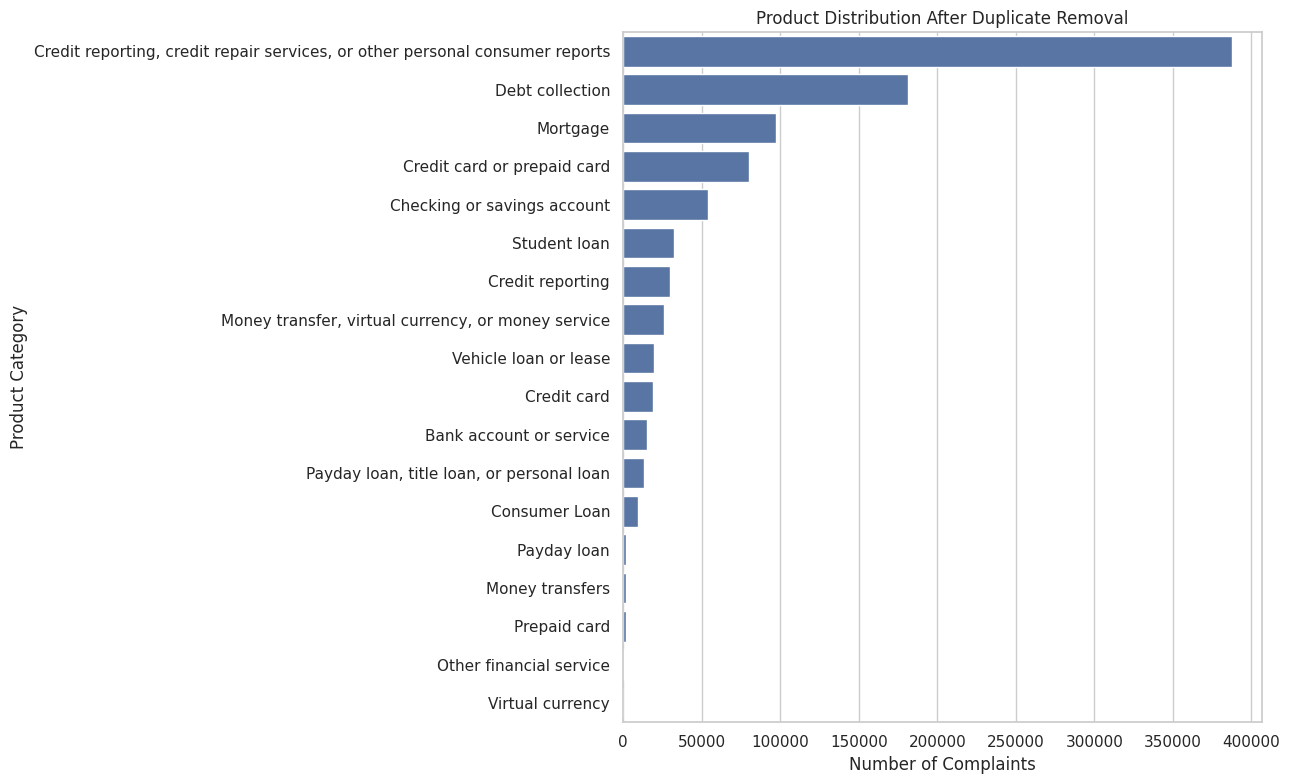

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 8))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.title('Product Distribution After Duplicate Removal')
plt.xlabel('Number of Complaints')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [56]:
majority_class = product_counts.idxmax()
minority_class = product_counts.idxmin()

print("Majority class:", majority_class)
print("Majority count:", product_counts.max())

print("\nMinority class:", minority_class)
print("Minority count:", product_counts.min())

print(
    "\nImbalance ratio:",
    round(product_counts.max() / product_counts.min(), 2)
)

Majority class: Credit reporting, credit repair services, or other personal consumer reports
Majority count: 387476

Minority class: Virtual currency
Minority count: 14

Imbalance ratio: 27676.86


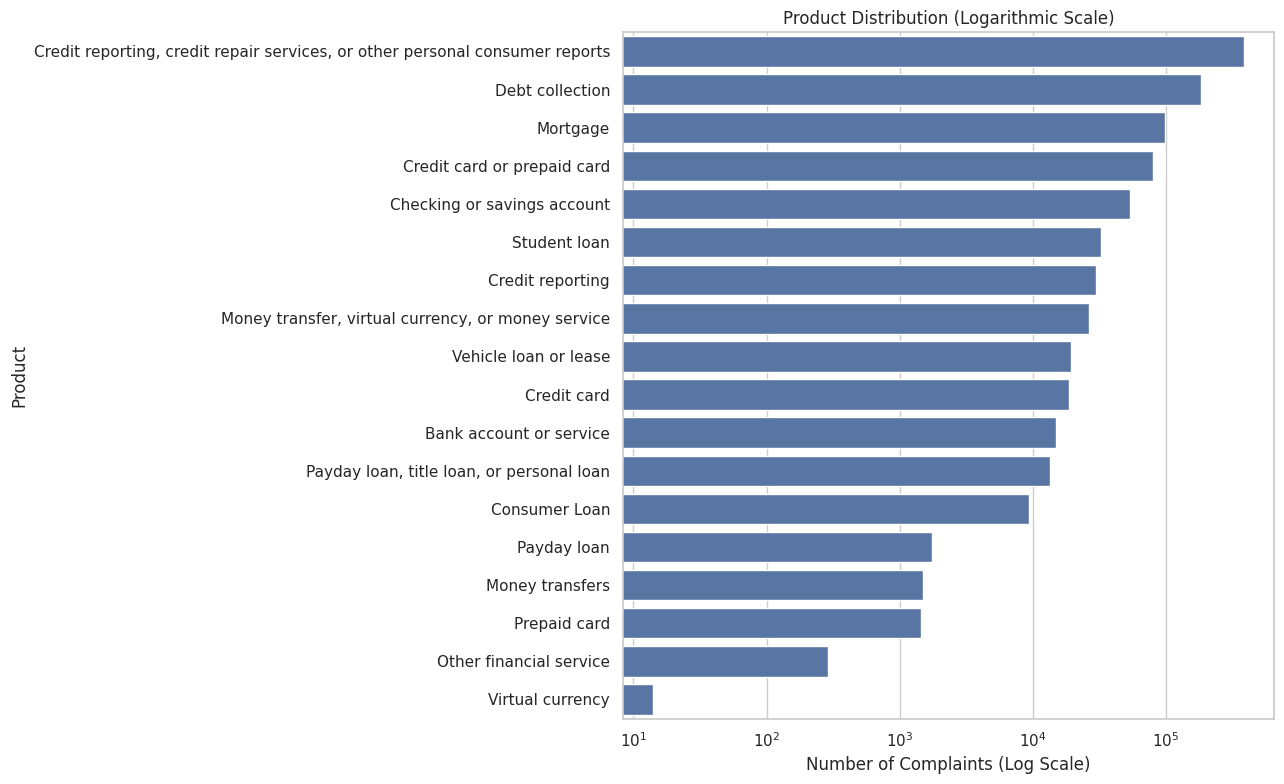

In [57]:
plt.figure(figsize=(13, 8))

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.xscale('log')

plt.title('Product Distribution (Logarithmic Scale)')
plt.xlabel('Number of Complaints (Log Scale)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

# Text length analysis

In [58]:
clean_df['char_count'] = clean_df[
    'Consumer complaint narrative'
].apply(len)

In [59]:
clean_df['word_count'] = clean_df[
    'Consumer complaint narrative'
].apply(lambda x: len(x.split()))

In [60]:
import re

clean_df['sentence_count'] = clean_df[
    'Consumer complaint narrative'
].apply(
    lambda x: len([
        s for s in re.split(r'[.!?]+', x) if s.strip()
    ])
)

In [61]:
clean_df[
    ['char_count', 'word_count', 'sentence_count']
].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,char_count,word_count,sentence_count
count,970109.000000,970109.000000,970109.000000
mean,1106.515271,199.399253,11.081527
std,1296.818824,230.164578,12.311042
min,4.000000,1.000000,1.000000
25%,408.000000,74.000000,4.000000
50%,741.000000,134.000000,8.000000
75%,1342.000000,243.000000,14.000000
90%,2316.000000,418.000000,23.000000
95%,3257.000000,587.000000,31.000000
99%,5922.920000,1075.000000,56.000000


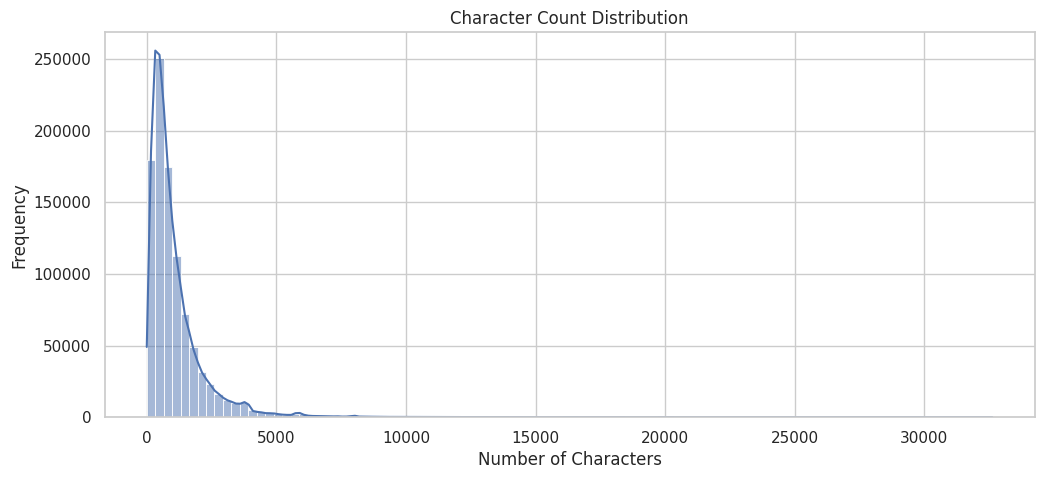

In [62]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=clean_df,
    x='char_count',
    bins=100,
    kde=True
)

plt.title('Character Count Distribution')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')

plt.show()

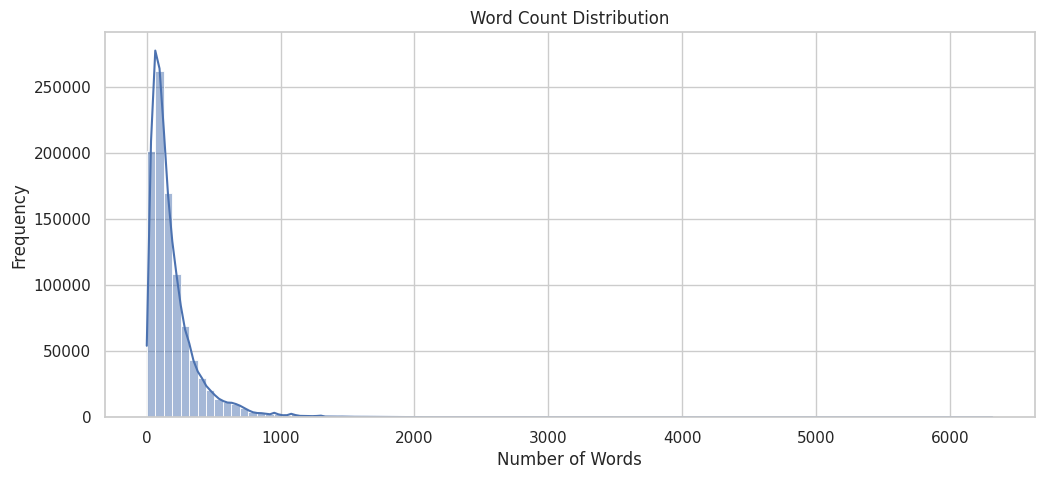

In [63]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=clean_df,
    x='word_count',
    bins=100,
    kde=True
)

plt.title('Word Count Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()

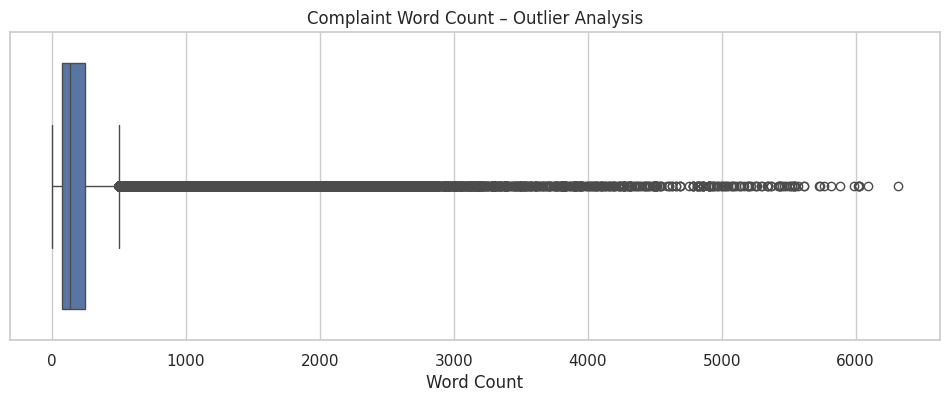

In [64]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=clean_df['word_count']
)

plt.title('Complaint Word Count – Outlier Analysis')
plt.xlabel('Word Count')

plt.show()

In [65]:
for i, text in enumerate(
    clean_df['Consumer complaint narrative'].sample(
        5, random_state=42
    ),
    1
):
    print(f"\nComplaint {i}:\n")
    print(text[:1500])
    print("-" * 100)


Complaint 1:

I am requesting the recordings Capital One holds of ALL conversations that took place between XX/XX/2016 to present. I 'm aware that all Capital One calls are recorded as stated by the Capital One employees, and I 'm requesting said calls due to the failed investigation and fraud that has taken place with Capital One. Please reference complaint submission, [ Case number : XXXX ]
----------------------------------------------------------------------------------------------------

Complaint 2:

i was issued a wrong modification with XXXX XXXX XXXX after loan was sold to them and in turn now a servicer spf wont help. my home is legally entitled toa loan reduction from sandy damage and a real modification. this loan change hands three times and nowforeclosure is in process.. no one cares no one helps but when i was need in XXXX i did my part.
----------------------------------------------------------------------------------------------------

Complaint 3:

On XX/XX/2021 my U

In [66]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Take a sample for EDA
sample_texts = clean_df[
    'Consumer complaint narrative'
].sample(
    50000,
    random_state=42
)

# Create unigram vectorizer
unigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(1, 1),
    max_features=30,
    min_df=5
)

unigram_matrix = unigram_vectorizer.fit_transform(sample_texts)

# Calculate word frequencies
unigram_counts = unigram_matrix.sum(axis=0).A1

unigram_df = pd.DataFrame({
    'Word': unigram_vectorizer.get_feature_names_out(),
    'Frequency': unigram_counts
}).sort_values(
    by='Frequency',
    ascending=False
)

display(unigram_df)

,Word,Frequency
29,xxxx,584653
28,xx,157261
9,credit,89320
1,account,77100
0,00,48968
23,report,41483
14,information,38883
20,payment,29603
24,reporting,27433
16,loan,25783


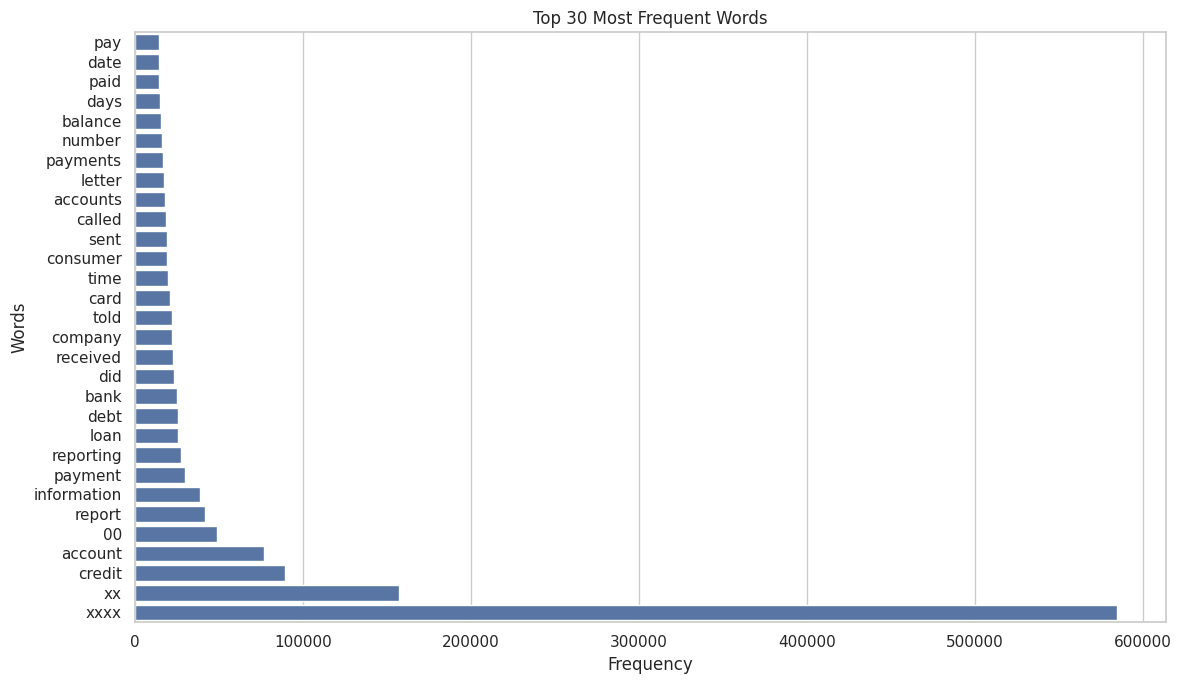

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    data=unigram_df.sort_values('Frequency'),
    x='Frequency',
    y='Word'
)

plt.title('Top 30 Most Frequent Words')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.tight_layout()
plt.show()

In [68]:
bigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(2, 2),
    max_features=30,
    min_df=5
)

bigram_matrix = bigram_vectorizer.fit_transform(sample_texts)

bigram_counts = bigram_matrix.sum(axis=0).A1

bigram_df = pd.DataFrame({
    'Bigram': bigram_vectorizer.get_feature_names_out(),
    'Frequency': bigram_counts
}).sort_values(
    by='Frequency',
    ascending=False
)

display(bigram_df)

,Bigram,Frequency
27,xxxx xxxx,298769
20,xx xx,77951
21,xx xxxx,58221
7,credit report,22371
26,xxxx xx,17335
22,xxxx account,9748
3,account xxxx,9094
8,credit reporting,8943
6,credit card,8689
0,00 xxxx,7136


In [69]:
trigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(3, 3),
    max_features=30,
    min_df=5
)

trigram_matrix = trigram_vectorizer.fit_transform(sample_texts)

trigram_counts = trigram_matrix.sum(axis=0).A1

trigram_df = pd.DataFrame({
    'Trigram': trigram_vectorizer.get_feature_names_out(),
    'Frequency': trigram_counts
}).sort_values(
    by='Frequency',
    ascending=False
)

display(trigram_df)

,Trigram,Frequency
26,xxxx xxxx xxxx,179557
17,xx xx xxxx,57345
22,xxxx xx xx,17309
19,xx xxxx xxxx,10691
25,xxxx xxxx xx,7727
18,xx xxxx xx,5500
23,xxxx xxxx account,5246
1,00 xxxx xxxx,4896
9,fair credit reporting,4782
6,credit reporting act,4743


In [70]:
!pip install wordcloud

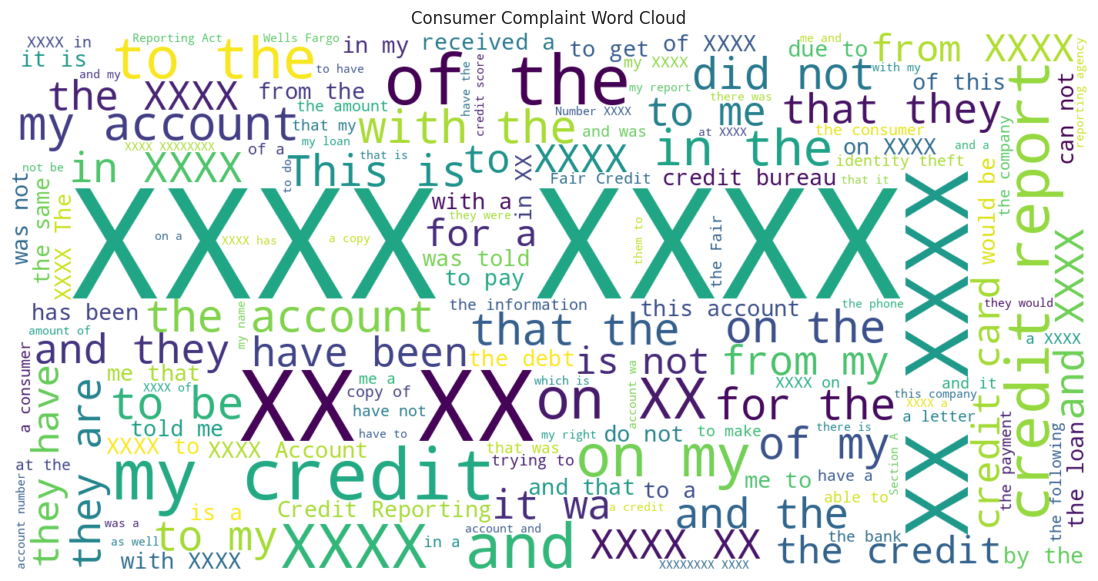

In [71]:
from wordcloud import WordCloud

text_data = ' '.join(sample_texts)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color='white',
    max_words=150,
    stopwords='english'
).generate(text_data)

plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Consumer Complaint Word Cloud')

plt.show()

In [72]:
stopwords='english'

In [73]:
import re

def clean_eda_text(text):

    text = text.lower()

    # Remove XXXX redaction placeholders
    text = re.sub(r'\bx+\b', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


sample_eda = sample_texts.apply(clean_eda_text)

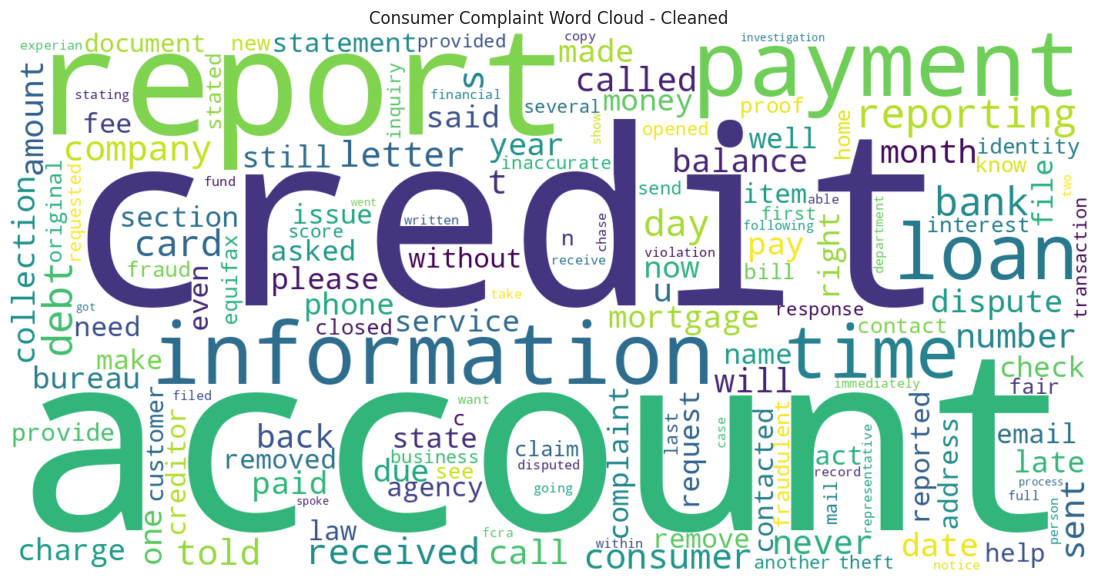

In [74]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

text_data = ' '.join(sample_eda)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color='white',
    max_words=150,
    stopwords=STOPWORDS,
    collocations=False
).generate(text_data)

plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Consumer Complaint Word Cloud - Cleaned')

plt.show()

In [75]:
from sklearn.feature_extraction.text import CountVectorizer

# Unigrams
unigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(1, 1),
    max_features=30,
    min_df=5
)

unigram_matrix = unigram_vectorizer.fit_transform(sample_eda)

unigram_df = pd.DataFrame({
    'Word': unigram_vectorizer.get_feature_names_out(),
    'Frequency': unigram_matrix.sum(axis=0).A1
}).sort_values('Frequency', ascending=False)

display(unigram_df)

,Word,Frequency
8,credit,89309
0,account,77112
24,report,41482
13,information,38880
21,payment,29601
25,reporting,27420
15,loan,25784
11,debt,25435
3,bank,24873
12,did,23303


In [76]:
bigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(2, 2),
    max_features=30,
    min_df=5
)

bigram_matrix = bigram_vectorizer.fit_transform(sample_eda)

bigram_df = pd.DataFrame({
    'Bigram': bigram_vectorizer.get_feature_names_out(),
    'Frequency': bigram_matrix.sum(axis=0).A1
}).sort_values('Frequency', ascending=False)

display(bigram_df)

,Bigram,Frequency
10,credit report,22386
11,credit reporting,8942
8,credit card,8691
17,identity theft,6208
7,credit bureaus,5802
16,fair credit,5194
23,reporting act,4848
1,account number,4464
29,wells fargo,4351
25,reporting agency,4191


In [77]:
trigram_vectorizer = CountVectorizer(
    stop_words='english',
    ngram_range=(3, 3),
    max_features=30,
    min_df=5
)

trigram_matrix = trigram_vectorizer.fit_transform(sample_eda)

trigram_df = pd.DataFrame({
    'Trigram': trigram_vectorizer.get_feature_names_out(),
    'Frequency': trigram_matrix.sum(axis=0).A1
}).sort_values('Frequency', ascending=False)

display(trigram_df)

,Trigram,Frequency
12,fair credit reporting,4770
9,credit reporting act,4733
7,consumer reporting agency,3292
10,credit reporting agencies,1856
26,states consumer reporting,1831
23,section states consumer,1772
19,reporting agency furnish,1759
28,victim identity theft,1685
0,accordance fair credit,1678
5,agency furnish account,1646


In [78]:
product_text_analysis = clean_df.groupby('Product').agg(
    total_complaints=('word_count', 'count'),
    average_words=('word_count', 'mean'),
    median_words=('word_count', 'median'),
    average_characters=('char_count', 'mean')
).sort_values(
    by='total_complaints',
    ascending=False
)

display(product_text_analysis)

,total_complaints,average_words,median_words,average_characters
Product,,,,
"Credit reporting, credit repair services, or other personal consumer reports",387476,166.516016,113.0,941.607958
Debt collection,181437,177.811091,115.0,985.009910
Mortgage,97507,298.484160,216.0,1652.765227
Credit card or prepaid card,80286,233.377837,171.0,1278.658371
Checking or savings account,54018,244.431319,174.0,1331.605021
Student loan,32484,234.944588,173.0,1292.944311
Credit reporting,29775,137.157615,93.0,762.835197
"Money transfer, virtual currency, or money service",26238,224.247923,154.0,1222.873542
Vehicle loan or lease,19450,254.861748,178.0,1379.988175


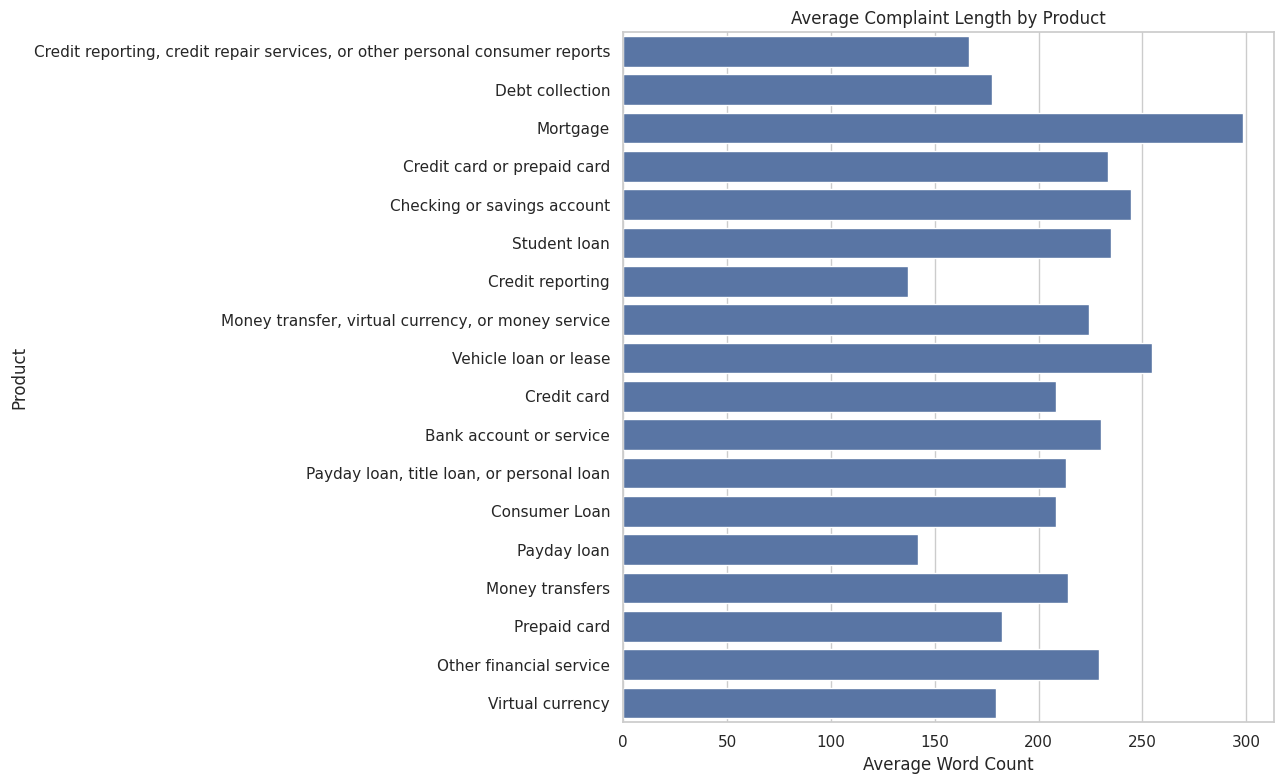

In [79]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=product_text_analysis.reset_index(),
    x='average_words',
    y='Product'
)

plt.title('Average Complaint Length by Product')
plt.xlabel('Average Word Count')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [80]:
top_products = clean_df['Product'].value_counts().head(5).index

for product in top_products:

    product_texts = clean_df.loc[
        clean_df['Product'] == product,
        'Consumer complaint narrative'
    ].sample(
        n=min(
            5000,
            (clean_df['Product'] == product).sum()
        ),
        random_state=42
    )

    print("\nPRODUCT:", product)

    vectorizer = CountVectorizer(
        stop_words='english',
        max_features=15,
        min_df=3
    )

    matrix = vectorizer.fit_transform(
        product_texts.apply(clean_eda_text)
    )

    frequencies = matrix.sum(axis=0).A1

    result = pd.DataFrame({
        'Word': vectorizer.get_feature_names_out(),
        'Frequency': frequencies
    }).sort_values(
        by='Frequency',
        ascending=False
    )

    display(result)


PRODUCT: Credit reporting, credit repair services, or other personal consumer reports


,Word,Frequency
4,credit,13278
0,account,7819
12,report,7222
8,information,5916
13,reporting,5205
3,consumer,3249
1,accounts,3120
14,section,2327
5,date,2146
2,balance,1853



PRODUCT: Debt collection


,Word,Frequency
5,debt,8769
4,credit,8094
0,account,5771
2,collection,3725
3,company,3637
7,information,3515
11,report,3388
10,received,2638
8,letter,2414
12,reporting,2200



PRODUCT: Mortgage


,Word,Frequency
6,loan,11346
7,mortgage,11057
9,payment,7874
10,payments,4892
14,told,4742
5,home,4651
11,received,4413
0,account,4282
1,bank,4106
13,time,3964



PRODUCT: Credit card or prepaid card


,Word,Frequency
4,card,11913
7,credit,11359
0,account,8816
2,bank,4694
10,payment,4229
3,called,3615
14,told,3600
8,did,3456
11,received,3411
13,time,3003



PRODUCT: Checking or savings account


,Word,Frequency
0,account,17839
1,bank,10859
10,money,4978
14,told,4212
5,check,3907
2,called,3467
9,funds,3329
3,card,3233
8,did,3198
6,checking,2959


In [81]:
product_text_analysis = clean_df.groupby('Product').agg(
    total_complaints=('word_count', 'count'),
    average_words=('word_count', 'mean'),
    median_words=('word_count', 'median'),
    average_characters=('char_count', 'mean')
).sort_values(
    by='total_complaints',
    ascending=False
)

display(product_text_analysis)

,total_complaints,average_words,median_words,average_characters
Product,,,,
"Credit reporting, credit repair services, or other personal consumer reports",387476,166.516016,113.0,941.607958
Debt collection,181437,177.811091,115.0,985.009910
Mortgage,97507,298.484160,216.0,1652.765227
Credit card or prepaid card,80286,233.377837,171.0,1278.658371
Checking or savings account,54018,244.431319,174.0,1331.605021
Student loan,32484,234.944588,173.0,1292.944311
Credit reporting,29775,137.157615,93.0,762.835197
"Money transfer, virtual currency, or money service",26238,224.247923,154.0,1222.873542
Vehicle loan or lease,19450,254.861748,178.0,1379.988175


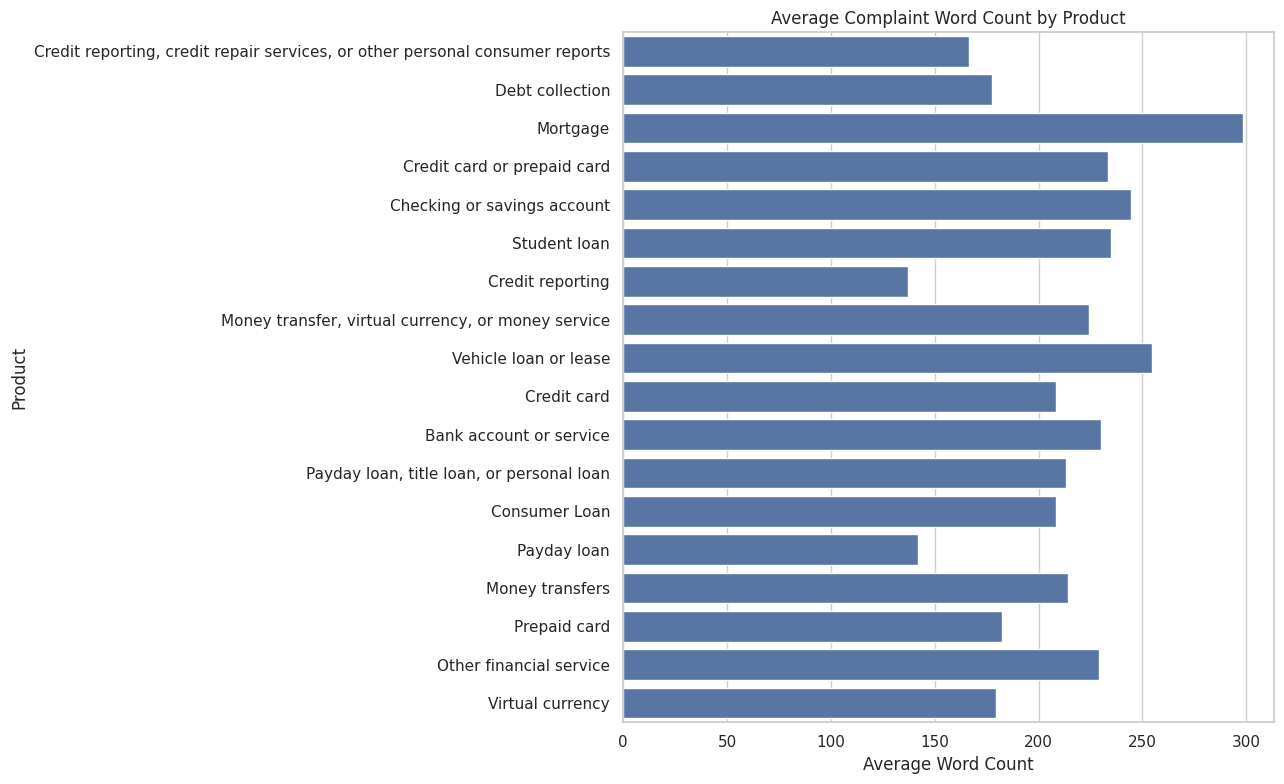

In [83]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=product_text_analysis.reset_index(),
    x='average_words',
    y='Product'
)

plt.title('Average Complaint Word Count by Product')
plt.xlabel('Average Word Count')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [82]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

top_products = clean_df['Product'].value_counts().head(5).index

for product in top_products:

    texts = clean_df.loc[
        clean_df['Product'] == product,
        'Consumer complaint narrative'
    ].sample(
        n=5000,
        random_state=42
    ).apply(clean_eda_text)

    vectorizer = TfidfVectorizer(
        stop_words='english',
        max_features=5000,
        min_df=3
    )

    matrix = vectorizer.fit_transform(texts)

    mean_scores = np.asarray(
        matrix.mean(axis=0)
    ).flatten()

    top_indices = mean_scores.argsort()[-15:][::-1]

    words = vectorizer.get_feature_names_out()

    print("\nPRODUCT:", product)

    for idx in top_indices:
        print(words[idx], round(mean_scores[idx], 4))


PRODUCT: Credit reporting, credit repair services, or other personal consumer reports
credit 0.0788
account 0.0688
report 0.0554
reporting 0.0471
information 0.0435
accounts 0.0384
section 0.0379
consumer 0.031
states 0.0253
equifax 0.0243
balance 0.0236
date 0.0222
experian 0.0219
inquiry 0.0219
late 0.0215

PRODUCT: Debt collection
debt 0.0656
credit 0.0579
account 0.0518
company 0.0393
report 0.0363
collection 0.0349
information 0.0293
received 0.0267
letter 0.0263
paid 0.0236
sent 0.0232
called 0.023
phone 0.0216
number 0.0215
reporting 0.0214

PRODUCT: Mortgage
loan 0.0544
mortgage 0.0529
payment 0.0476
payments 0.0333
bank 0.0306
account 0.0298
home 0.0291
told 0.0286
company 0.0281
modification 0.0264
received 0.0257
escrow 0.0252
credit 0.0248
time 0.023
did 0.0225

PRODUCT: Credit card or prepaid card
card 0.0637
credit 0.0628
account 0.055
bank 0.0374
payment 0.0372
balance 0.0276
received 0.0267
late 0.0259
called 0.0258
told 0.0257
did 0.0251
charges 0.023
capital 0.0226
c

In [84]:
clean_df.to_csv(
    'consumer_complaints_cleaned.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


EDA – Observations and Activities Performed
- Downloaded the Consumer Complaints dataset using KaggleHub.
- Loaded the dataset into Pandas and examined its dimensions, columns and data types.
- Performed missing-value analysis and calculated missing-value percentages.
- Identified that only 35.93% of records contained complaint narratives.
- Selected Consumer complaint narrative as the independent variable (X) and Product as the dependent variable (y).
- Identified 18 unique product categories.
- Calculated product-wise complaint counts and percentage distributions.
- Visualized product distribution using bar charts and logarithmic scaling.
- Identified severe class imbalance, with an imbalance ratio of 27,676.86:1.
- Identified 140,519 duplicate narrative occurrences (12.64%).
- Checked unique complaint narratives and duplicate records.
- Identified 702 conflicting narrative groups involving 12,238 records.
- Removed narratives associated with conflicting product labels.
- Removed exact duplicate narratives while retaining one occurrence of each unique complaint.
- Created a cleaned dataset containing 970,109 unique complaint narratives.
- Verified missing values, duplicate records and conflicting labels in the cleaned dataset.
- Calculated character counts for all complaint narratives.
- Calculated word counts and sentence counts for all complaint narratives.
- Generated descriptive statistics including mean, median, standard deviation, percentiles and maximum values.
- Visualized character and word count distributions using histograms.
- Used boxplots to identify unusually long complaint narratives.
- Inspected the shortest and longest complaint narratives.
- Identified the right-skewed distribution of complaint lengths.
- Extracted unigrams using CountVectorizer and identified the most frequent individual words.
- Extracted bigrams to analyze frequently occurring two-word combinations.
- Extracted trigrams to analyze frequently occurring three-word combinations.
- Applied stopword removal for frequency-based text analysis.
- Generated word cloud visualizations to understand common complaint vocabulary.
- Removed redaction placeholders (XXXX), URLs and unnecessary characters for improved EDA visualization.
- Performed product-wise vocabulary analysis on the five largest product categories.
- Compared frequently occurring words across different financial product categories.
- Investigated domain-specific vocabulary associated with credit reporting, debt collection, mortgages, credit cards and banking accounts.